Dataset shape: (569, 31)
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst texture  worst perimeter  wor

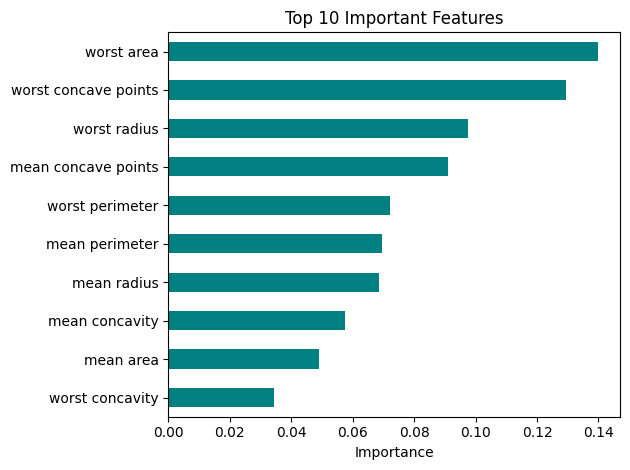

In [1]:
# ============================================
# Breast Cancer Prediction using Machine Learning
# ============================================

# 1. Import libraries
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 2. Load the dataset
data = load_breast_cancer()
df = pd.DataFrame(data.data, columns=data.feature_names)
df["target"] = data.target   # 0 = malignant (cancerous), 1 = benign (non-cancerous)
print("Dataset shape:", df.shape)
print(df.head())

# 3. Separate input features (X) and output label (y)
X = df.drop("target", axis=1)
y = df["target"]

# 4. Split into training (80%) and testing (20%) sets
#    stratify keeps the class proportions equal in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 5. Feature scaling (bring all features to the same range)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 6. Model 1: Logistic Regression
lr = LogisticRegression(max_iter=5000)
lr.fit(X_train_scaled, y_train)
lr_pred = lr.predict(X_test_scaled)

# 7. Model 2: Random Forest
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)

# 8. Compare model accuracy
print("\nLogistic Regression Accuracy:", round(accuracy_score(y_test, lr_pred) * 100, 2), "%")
print("Random Forest Accuracy:", round(accuracy_score(y_test, rf_pred) * 100, 2), "%")

# 9. Detailed report for the best model
print("\nClassification Report (Logistic Regression):")
print(classification_report(y_test, lr_pred, target_names=data.target_names))

print("Confusion Matrix:")
print(confusion_matrix(y_test, lr_pred))

# 10. Plot the most important features
imp = pd.Series(rf.feature_importances_, index=X.columns)
imp.nlargest(10).sort_values().plot(kind="barh", color="teal")
plt.title("Top 10 Important Features")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()